# House Price Prediction

## Model Training and Evaluation

This notebook implements and evaluates machine learning
regression models for predicting house sale prices.

Models:
- Dummy Regressor (Baseline)
- Linear Regression
- Random Forest Regressor
- Gradient Boosting Regressor

Evaluation metrics:
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    cross_validate
)

from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
BASE_DIR = Path.cwd()

if not (BASE_DIR / "data").exists():
    BASE_DIR = BASE_DIR.parent

data_path = BASE_DIR / "data" / "house_prices.csv"

df = pd.read_csv(data_path)

df = df.drop_duplicates()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "FullBath",
    "YearBuilt",
    "YearRemodAdd",
    "BedroomAbvGr",
    "LotArea",
    "Neighborhood",
    "HouseStyle",
    "ExterQual"
]

X = df[features].copy()
y = df["SalePrice"].copy()

print("Number of features:", X.shape[1])
print("Number of samples:", X.shape[0])

Number of features: 12
Number of samples: 1460


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1168
Testing samples: 292


In [5]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [6]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [7]:
sample_house = X_train.iloc[[0]]

predicted_price = linear_model.predict(sample_house)[0]

actual_price = y_train.iloc[0]

print("Predicted price:", round(predicted_price, 2))
print("Actual price:", actual_price)
print("Absolute error:", round(abs(
    actual_price - predicted_price
), 2))

Predicted price: 132468.12
Actual price: 145000
Absolute error: 12531.88


In [8]:
models = {
    "Baseline": DummyRegressor(
        strategy="median"
    ),

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

print("Models created successfully!")

Models created successfully!


In [9]:

from sklearn.base import clone

results = []

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            ("model", clone(model))
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring=scoring
    )

    results.append({
        "Model": name,
        "MAE": -scores["test_mae"].mean(),
        "RMSE": -scores["test_rmse"].mean(),
        "R2": scores["test_r2"].mean()
    })

    print(f"{name} evaluated successfully!")

results_df = pd.DataFrame(results)

results_df = results_df.sort_values("RMSE")

results_df.round(3)

Baseline evaluated successfully!
Linear Regression evaluated successfully!
Random Forest evaluated successfully!
Gradient Boosting evaluated successfully!


,Model,MAE,RMSE,R2
3,Gradient Boosting,18970.184,30730.493,0.835
2,Random Forest,19563.461,32083.998,0.820
1,Linear Regression,21429.070,34708.117,0.794
0,Baseline,54617.145,78846.692,-0.053


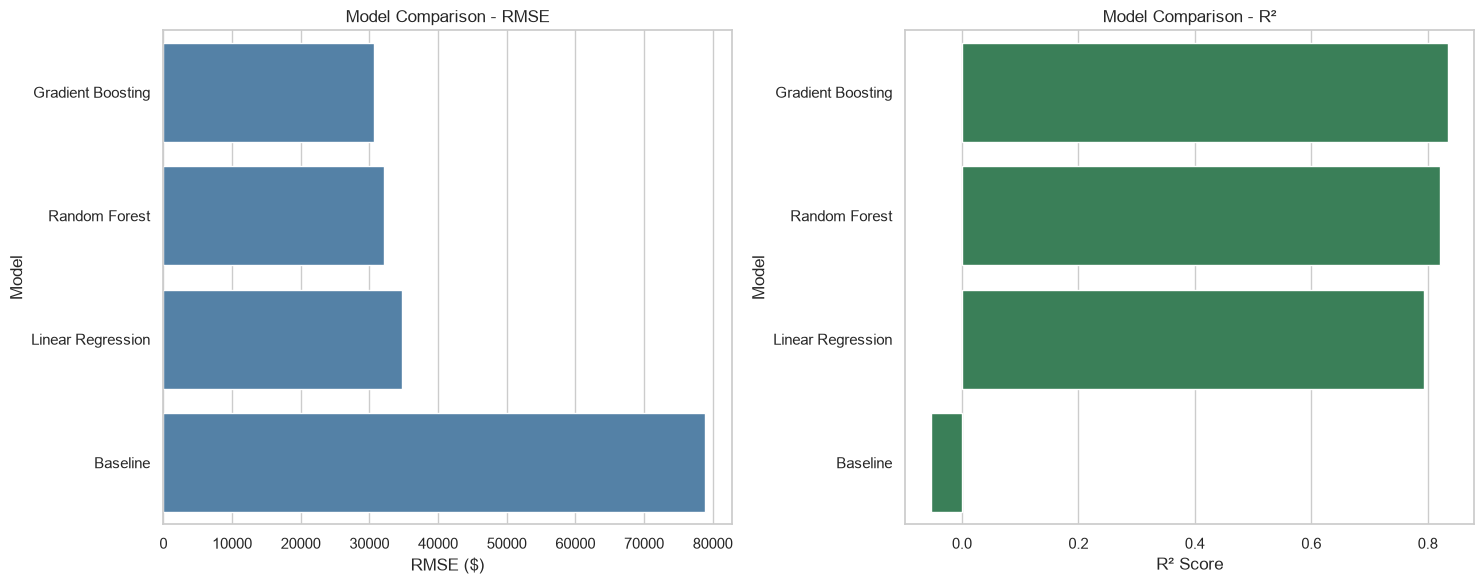

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=results_df,
    x="RMSE",
    y="Model",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Model Comparison - RMSE")
axes[0].set_xlabel("RMSE ($)")

sns.barplot(
    data=results_df,
    x="R2",
    y="Model",
    ax=axes[1],
    color="seagreen"
)

axes[1].set_title("Model Comparison - R²")
axes[1].set_xlabel("R² Score")

plt.tight_layout()
plt.show()

In [11]:
best_model_name = results_df.iloc[0]["Model"]

print("Best model:", best_model_name)

best_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", clone(models[best_model_name]))
    ]
)

best_model.fit(X_train, y_train)

print("Best model trained successfully!")

Best model: Gradient Boosting
Best model trained successfully!


In [12]:
y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("FINAL TEST RESULTS")
print("------------------")
print("Model:", best_model_name)
print(f"MAE: ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

FINAL TEST RESULTS
------------------
Model: Gradient Boosting
MAE: $17,363.37
RMSE: $26,803.77
R² Score: 0.9063


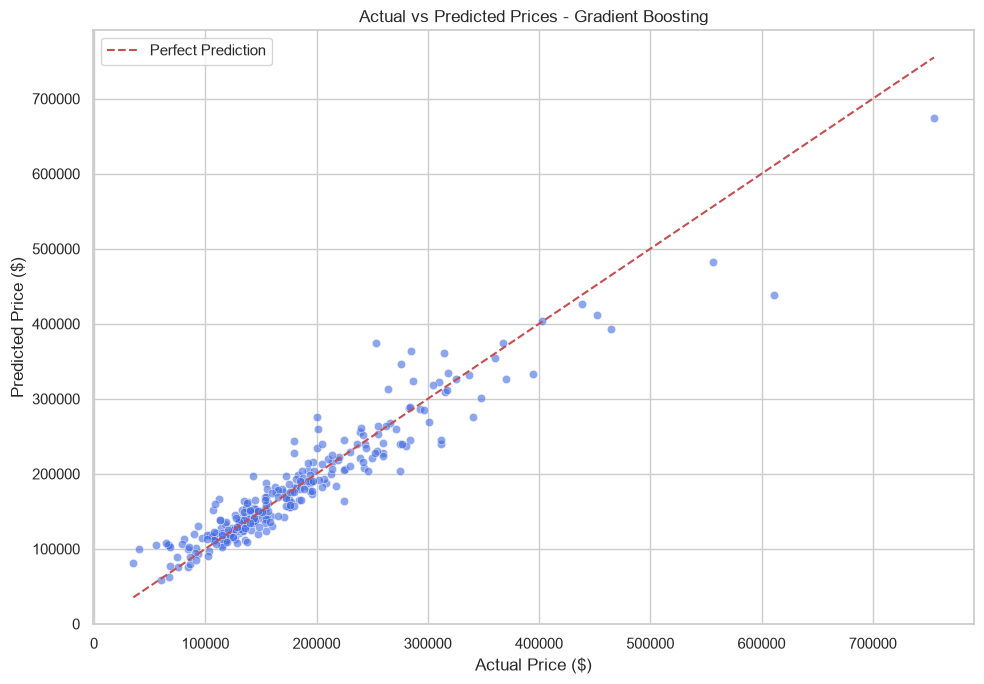

In [13]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.6,
    color="royalblue"
)

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--",
    label="Perfect Prediction"
)

plt.title(f"Actual vs Predicted Prices - {best_model_name}")
plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.legend()

plt.tight_layout()
plt.show()

In [14]:
models_dir = BASE_DIR / "models"

models_dir.mkdir(exist_ok=True)

model_path = models_dir / "house_price_model.joblib"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Model location:", model_path)

Model saved successfully!
Model location: c:\Users\User\OneDrive\Documents\GithubProjects\house-price-prediction\models\house_price_model.joblib


In [15]:
loaded_model = joblib.load(model_path)

sample = X_test.iloc[[0]]

prediction = loaded_model.predict(sample)[0]

print(f"Predicted price: ${prediction:,.2f}")
print(f"Actual price: ${y_test.iloc[0]:,.2f}")

Predicted price: $141,744.44
Actual price: $154,500.00


In [16]:
import json

metrics = {
    "model": best_model_name,
    "mae": float(mae),
    "rmse": float(rmse),
    "r2": float(r2),
    "training_samples": len(X_train),
    "testing_samples": len(X_test),
    "features": features
}

metrics_path = models_dir / "metrics.json"

with open(metrics_path, "w") as file:
    json.dump(metrics, file, indent=4)

results_df.to_csv(
    models_dir / "model_comparison.csv",
    index=False
)

print("Model evaluation results saved!")

Model evaluation results saved!
